# Superstore Sales Analysis Using Python

## Project Overview
This project analyses Superstore sales data to identify business trends, profitability patterns, customer behaviour and product performance.

## Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Seaborn

## Project Objectives
- Analyse sales and profit performance.
- Identify top-performing products and regions.
- Understand customer segments.
- Examine the impact of discounts and shipping modes.
- Generate actionable business recommendations.

## 1. Data Loading and Data Cleaning

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print('All libraries imported successfully')

All libraries imported successfully


In [45]:
import pandas as pd

df = pd.read_csv('Superstore_dataset.csv', encoding='cp1252')
print('Dataset is loaded Successfullt')
print("Dataset Shape:",df.shape)
df.head()

Dataset is loaded Successfullt
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
print("Dataset Shape:",df.shape)

Dataset Shape: (9994, 21)


In [4]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [6]:
print("Duplicate Rows:",df.duplicated().sum())

Duplicate Rows: 0


In [7]:
print(df[["Order Date","Ship Date"]].dtypes)

Order Date    str
Ship Date     str
dtype: object


In [30]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'], format='mixed', dayfirst=False
)
df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], format='mixed', dayfirst=False
)
print(df[['Order Date','Ship Date']].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [9]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


## 2. Exploratory Data Analysis

In [10]:
df[['Sales','Profit','Quantity','Discount']].describe()

,Sales,Profit,Quantity,Discount
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,3.789574,0.156203
std,623.245101,234.260108,2.225110,0.206452
min,0.444000,-6599.978000,1.000000,0.000000
25%,17.280000,1.728750,2.000000,0.000000
50%,54.490000,8.666500,3.000000,0.200000
75%,209.940000,29.364000,5.000000,0.200000
max,22638.480000,8399.976000,14.000000,0.800000


In [11]:
df[['Ship Mode','Segment','Region','Category','Sub-Category']].describe()

,Ship Mode,Segment,Region,Category,Sub-Category
count,9994,9994,9994,9994,9994
unique,4,3,4,3,17
top,Standard Class,Consumer,West,Office Supplies,Binders
freq,5968,5191,3203,6026,1523


In [12]:
df['Category'].value_counts()

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

In [13]:
df['Sub-Category'].value_counts()

Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64

In [14]:
df[['Sales','Profit','Quantity','Discount']].sum()

Sales       2.297201e+06
Profit      2.863970e+05
Quantity    3.787300e+04
Discount    1.561090e+03
dtype: float64

In [15]:
df.groupby('Category')['Profit'].sum()

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64

In [16]:
df.groupby('Region')['Sales'].sum()

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64

In [15]:
df.groupby('Segment')['Sales'].sum()

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64

In [19]:
print(df['Order Date'].dtype)
df['Order Date'].head()

str


0    11-08-2016
1    11-08-2016
2    06-12-2016
3    10-11-2015
4    10-11-2015
Name: Order Date, dtype: str

In [21]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='mixed',
    dayfirst=False
)

print(df['Order Date'].dtype)
df['Order Date'].head()

datetime64[us]


0   2016-11-08
1   2016-11-08
2   2016-06-12
3   2015-10-11
4   2015-10-11
Name: Order Date, dtype: datetime64[us]

In [22]:
df['Month'] = df['Order Date'].dt.month

In [23]:
df[['Order Date','Month']].head()

,Order Date,Month
0,2016-11-08,11
1,2016-11-08,11
2,2016-06-12,6
3,2015-10-11,10
4,2015-10-11,10


## 3. Sales Analysis

In [24]:
monthly_sales = df.groupby('Month')['Sales'].sum()
monthly_sales

Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64

In [22]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Month']


In [25]:
print(df.groupby('Month')['Sales'].sum().to_string())

Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035


In [26]:
monthly_sales=df.groupby('Month')['Sales'].sum()
monthly_sales

Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64

In [27]:
monthly_sales.idxmax()

np.int32(11)

In [28]:
monthly_sales.idxmin()

np.int32(2)

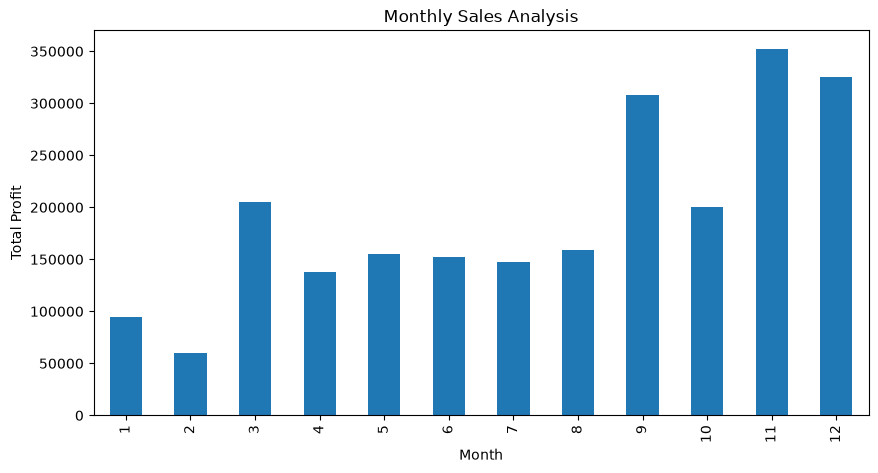

In [29]:
import matplotlib.pyplot as plt
monthly_sales.plot(kind='bar',figsize=(10,5))

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.show()

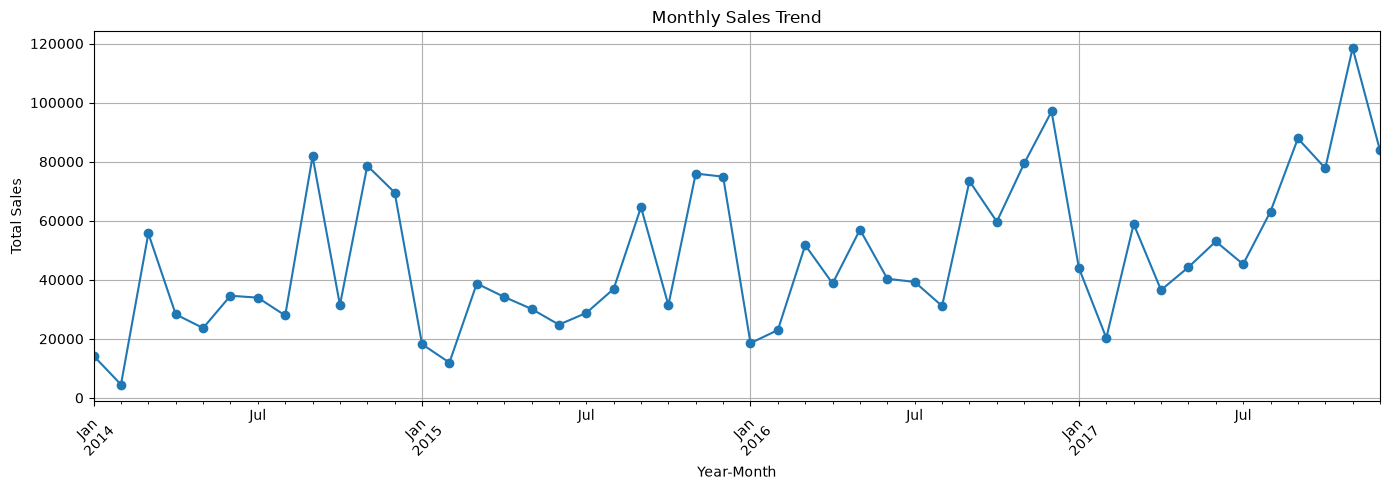

In [28]:
df['Year_Month'] = df['Order Date'].dt.to_period('M')
monthly_trend = df.groupby('Year_Month')['Sales'].sum()

plt.figure(figsize=(14, 5))
monthly_trend.plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

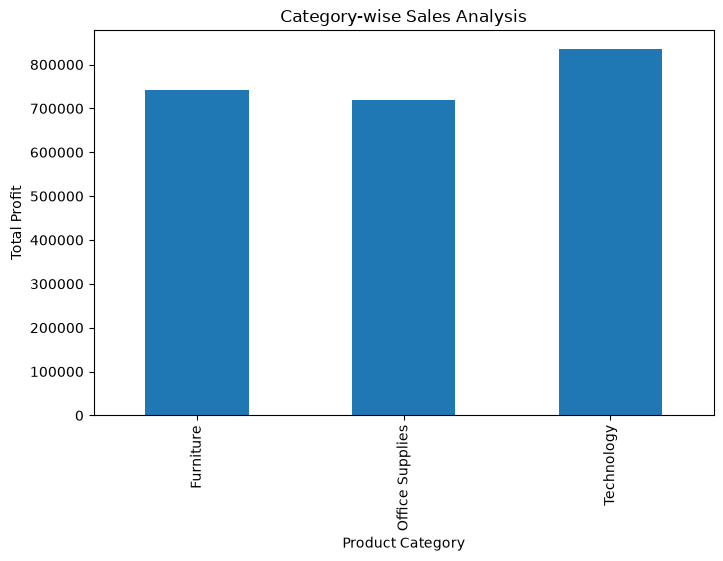

In [29]:
category_sales=df.groupby('Category')['Sales'].sum()
category_sales.plot(kind='bar',figsize=(8,5))
plt.title('Category-wise Sales Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.show()

In [30]:
print(category_sales.idxmax())

Technology


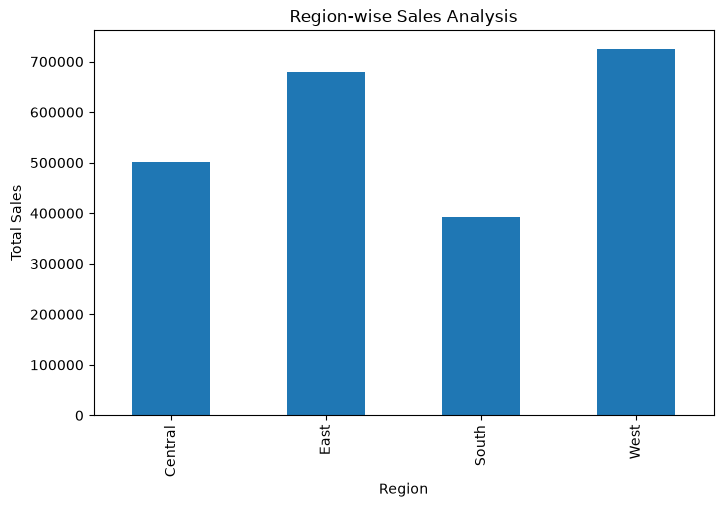

In [31]:
region_sales=df.groupby('Region')['Sales'].sum()
region_sales.plot(kind='bar',figsize=(8,5))

plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

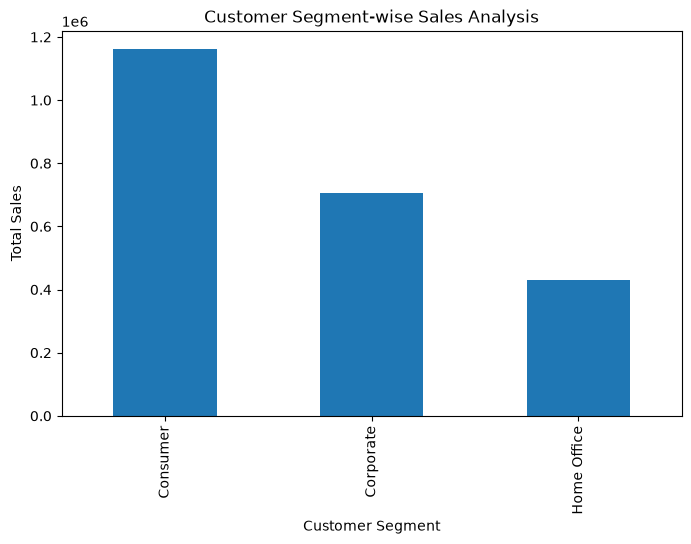

In [32]:
segment_sales=df.groupby('Segment')['Sales'].sum()
segment_sales.plot(kind='bar',figsize=(8,5))
plt.title('Customer Segment-wise Sales Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.show()

## 4. Profitability Analysis

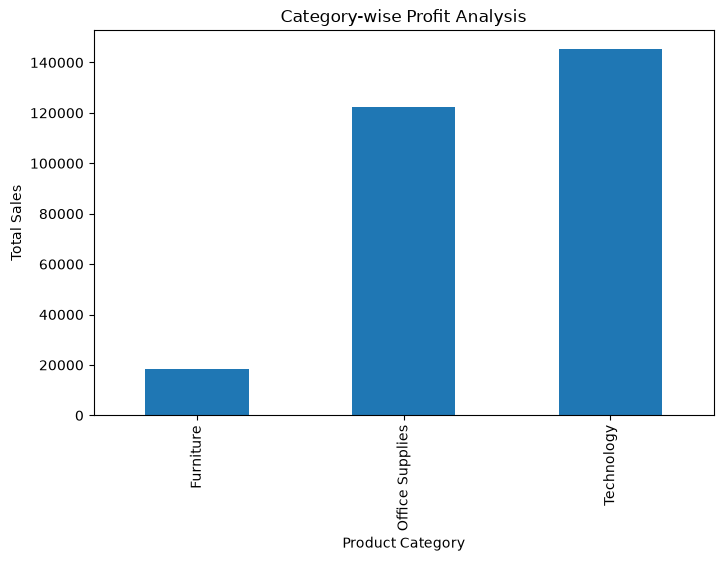

In [33]:
category_profit=df.groupby('Category')['Profit'].sum()
category_profit.plot(kind='bar',figsize=(8,5))
plt.title('Category-wise Profit Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.show()

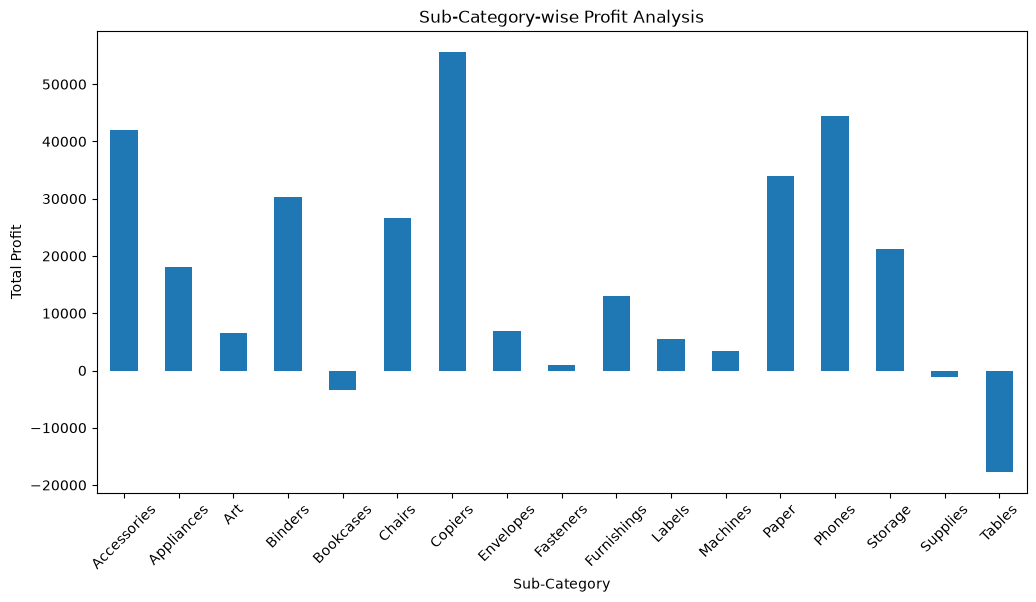

In [34]:
subcategory_profit=df.groupby('Sub-Category')['Profit'].sum()
subcategory_profit.plot(kind='bar',figsize=(12,6))
plt.title('Sub-Category-wise Profit Analysis')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.show()


In [35]:
print(subcategory_profit.idxmax())
print(subcategory_profit.idxmin())

Copiers
Tables


In [36]:
df[['Order Date','Ship Date']].head()

,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


In [162]:
df['Order Date']=pd.to_datetime(df['Order Date'])
df['Ship Date']=pd.to_datetime(df['Ship Date'])

In [161]:
df['Month']=df['Order Date'].dt.month

In [159]:
average_discount=df['Discount'].mean()
print(average_discount)

0.1562027216329798


In [160]:
discount_profit=df.groupby('Discount')['Profit'].mean()
print(discount_profit.to_string())

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797


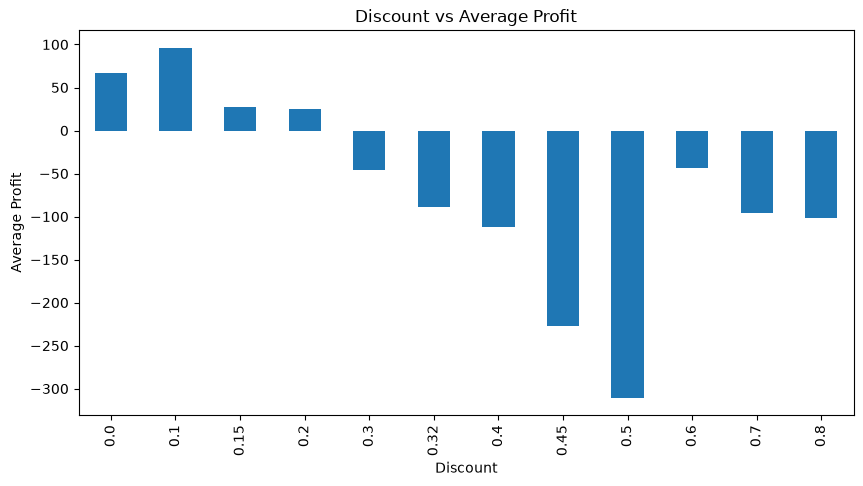

In [42]:
import matplotlib.pyplot as plt
discount_profit.plot(kind='bar',figsize=(10,5))
plt.title('Discount vs Average Profit')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.show()

In [43]:
total_sales=df['Sales'].sum()
total_profit=df['Profit'].sum()
print('Total Sales:',total_sales)
print('Total Profit:',total_profit)

Total Sales: 2297200.8603
Total Profit: 286397.0217


In [44]:
profit_margin=(total_profit/total_sales)*100
print('Profit Margin:',profit_margin)

Profit Margin: 12.467217240315605


In [45]:
shipmode_sales=df.groupby('Ship Mode')['Sales'].sum()
print(shipmode_sales)

Ship Mode
First Class       3.514284e+05
Same Day          1.283631e+05
Second Class      4.591936e+05
Standard Class    1.358216e+06
Name: Sales, dtype: float64


In [46]:
print(shipmode_sales.idxmax())
print(shipmode_sales.max())

Standard Class
1358215.743


In [47]:
shipmode_profit=df.groupby('Ship Mode')['Profit'].sum()
print(shipmode_profit)

Ship Mode
First Class        48969.8399
Same Day           15891.7589
Second Class       57446.6354
Standard Class    164088.7875
Name: Profit, dtype: float64


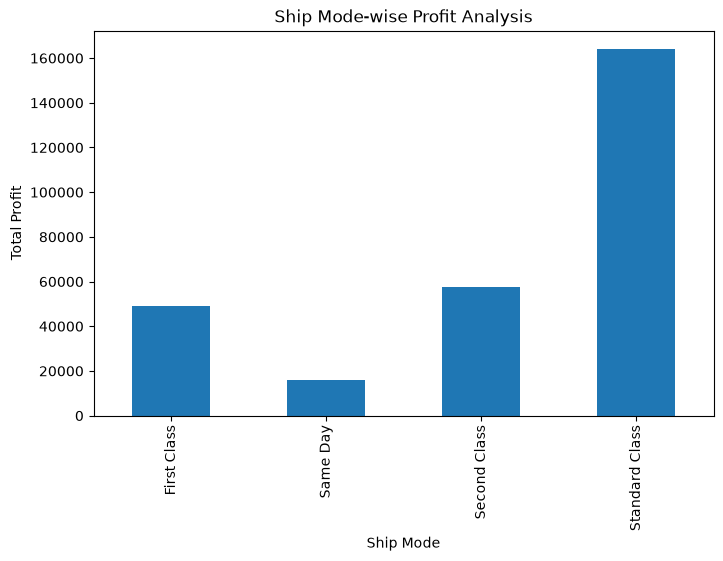

In [48]:
shipmode_profit.plot(kind='bar',figsize=(8,5))
plt.title('Ship Mode-wise Profit Analysis')
plt.xlabel('Ship Mode')
plt.ylabel('Total Profit')
plt.show()

In [49]:
print('Highest Profit:',shipmode_profit.idxmax())
print('Lowest Profit:',shipmode_profit.idxmin())

Highest Profit: Standard Class
Lowest Profit: Same Day


In [50]:
category_avg_sales=df.groupby('Category')['Sales'].mean()
print(category_avg_sales)

Category
Furniture          349.834887
Office Supplies    119.324101
Technology         452.709276
Name: Sales, dtype: float64


In [51]:
category_avg_profit=df.groupby('Category')['Profit'].mean()
print(category_avg_profit)

Category
Furniture           8.699327
Office Supplies    20.327050
Technology         78.752002
Name: Profit, dtype: float64


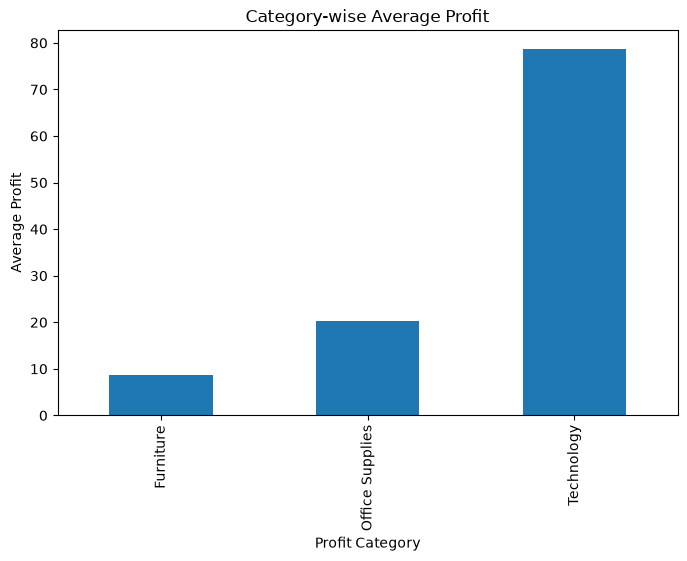

In [52]:
category_avg_profit.plot(kind='bar',figsize=(8,5))
plt.title('Category-wise Average Profit')
plt.xlabel('Profit Category')
plt.ylabel('Average Profit')
plt.show()

In [53]:
subcategory_avg_profit=df.groupby('Sub-Category')['Profit'].mean()
print(subcategory_avg_profit)

Sub-Category
Accessories     54.111788
Appliances      38.922758
Art              8.200737
Binders         19.843574
Bookcases      -15.230509
Chairs          43.095894
Copiers        817.909190
Envelopes       27.418019
Fasteners        4.375660
Furnishings     13.645918
Labels          15.236962
Machines        29.432669
Paper           24.856620
Phones          50.073938
Storage         25.152277
Supplies        -6.258418
Tables         -55.565771
Name: Profit, dtype: float64


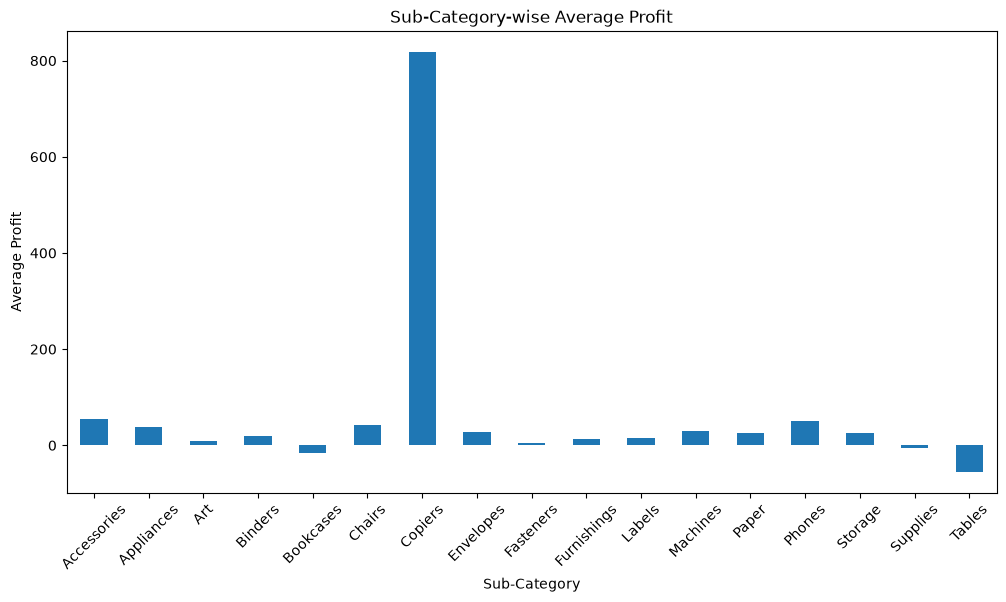

In [54]:
subcategory_avg_profit.plot(kind='bar',figsize=(12,6))
plt.title('Sub-Category-wise Average Profit')
plt.xlabel('Sub-Category')
plt.ylabel('Average Profit')
plt.xticks(rotation=45)
plt.show()

In [55]:
print('Highest Average Profit:',subcategory_avg_profit.idxmax())
print('Lowest Average Profit:',subcategory_avg_profit.idxmin())

Highest Average Profit: Copiers
Lowest Average Profit: Tables


## 5. Quantity Analysis

In [56]:
category_quantity=df.groupby('Category')['Quantity'].sum()
print(category_quantity)

Category
Furniture           8028
Office Supplies    22906
Technology          6939
Name: Quantity, dtype: int64


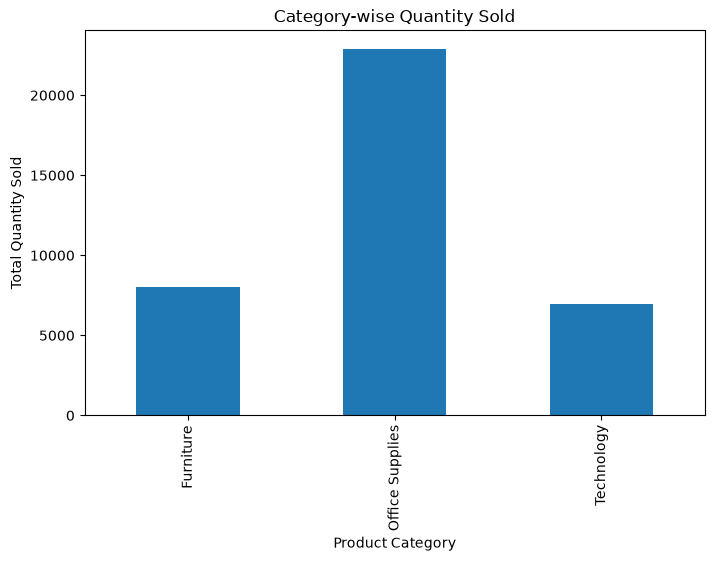

In [57]:
category_quantity.plot(kind='bar',figsize=(8,5))
plt.title('Category-wise Quantity Sold')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.show()

In [58]:
print('Highest Quantity:',category_quantity.idxmax())
print('Lowest Quantity:',category_quantity.idxmin())

Highest Quantity: Office Supplies
Lowest Quantity: Technology


In [59]:
subcategory_quantity=df.groupby('Sub-Category')['Quantity'].sum()
print(subcategory_quantity)

Sub-Category
Accessories    2976
Appliances     1729
Art            3000
Binders        5974
Bookcases       868
Chairs         2356
Copiers         234
Envelopes       906
Fasteners       914
Furnishings    3563
Labels         1400
Machines        440
Paper          5178
Phones         3289
Storage        3158
Supplies        647
Tables         1241
Name: Quantity, dtype: int64


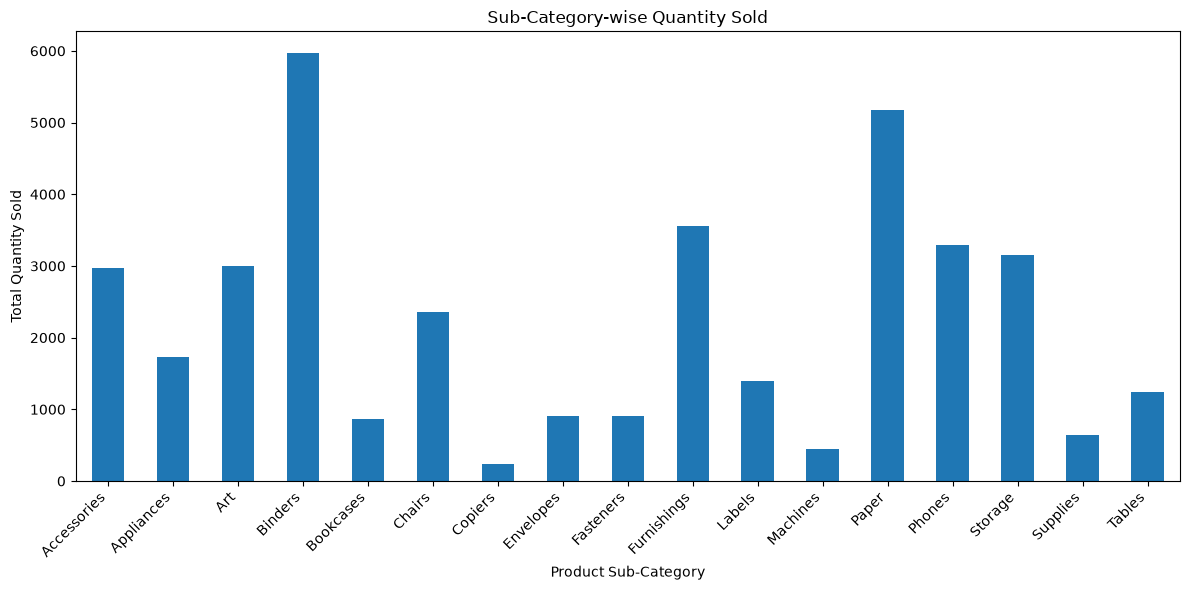

In [60]:
subcategory_quantity.plot(kind='bar', figsize=(12,6))
plt.title('Sub-Category-wise Quantity Sold')
plt.xlabel('Product Sub-Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [61]:
print('Highest Quantity:',subcategory_quantity.idxmax())
print('Lowest Quantity:',subcategory_quantity.idxmin())

Highest Quantity: Binders
Lowest Quantity: Copiers


## 6. Discount Analysis

In [62]:
discount_sales=df.groupby('Discount')['Sales'].sum()
print(discount_sales)

Discount
0.00    1.087908e+06
0.10    5.436935e+04
0.15    2.755852e+04
0.20    7.645944e+05
0.30    1.032267e+05
0.32    1.449346e+04
0.40    1.164178e+05
0.45    5.484974e+03
0.50    5.891854e+04
0.60    6.644700e+03
0.70    4.062028e+04
0.80    1.696376e+04
Name: Sales, dtype: float64


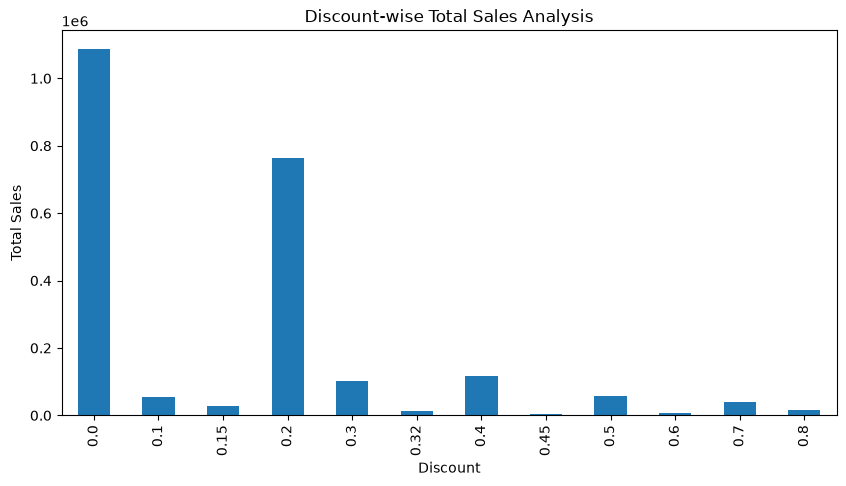

In [63]:
discount_sales.plot(kind='bar',figsize=(10,5))
plt.title('Discount-wise Total Sales Analysis')
plt.xlabel('Discount')
plt.ylabel('Total Sales')
plt.show()

In [64]:
print('Highest Sales Discount:',discount_sales.idxmax())
print('Lowest Sales Discount:',discount_sales.idxmin())

Highest Sales Discount: 0.0
Lowest Sales Discount: 0.45


In [65]:
discount_total_profit=df.groupby('Discount')['Profit'].sum()
print(discount_total_profit)

Discount
0.00    320987.6032
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64


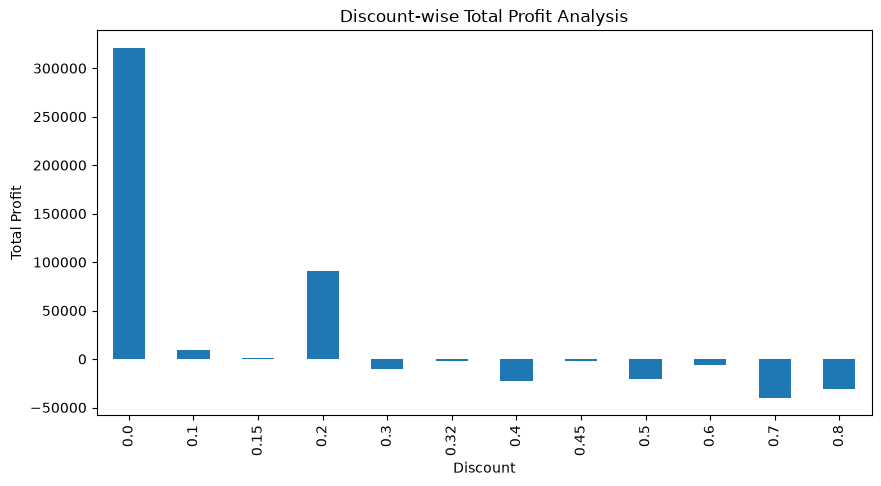

In [66]:
discount_total_profit.plot(kind='bar',figsize=(10,5))
plt.title('Discount-wise Total Profit Analysis')
plt.xlabel('Discount')
plt.ylabel('Total Profit')
plt.show()

In [67]:
print('Highest Profit Discount:',discount_total_profit.idxmax())
print('Lowest Profit Discount:',discount_total_profit.idxmin())

Highest Profit Discount: 0.0
Lowest Profit Discount: 0.7


In [68]:
discount_analysis = df.groupby('Discount').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Total_Orders=('Order ID', 'nunique'),
    Records=('Discount', 'count')
)
print(discount_analysis)

           Total_Sales  Average_Profit  Total_Orders  Records
Discount                                                     
0.00      1.087908e+06       66.900292          2644     4798
0.10      5.436935e+04       96.055074            89       94
0.15      2.755852e+04       27.288298            51       52
0.20      7.645944e+05       24.702572          2407     3657
0.30      1.032267e+05      -45.679636           211      227
0.32      1.449346e+04      -88.560656            27       27
0.40      1.164178e+05     -111.927429           185      206
0.45      5.484974e+03     -226.646464            10       11
0.50      5.891854e+04     -310.703456            64       66
0.60      6.644700e+03      -43.077212           127      138
0.70      4.062028e+04      -95.874060           344      418
0.80      1.696376e+04     -101.796797           250      300


## 7. Correlation Analysis

In [79]:
correlation=df['Sales'].corr(df['Profit'])
print('Sales and Profit Correlation:',correlation)

Sales and Profit Correlation: 0.4790643497377061


In [163]:
total_sales = df['Sales'].sum()
total_orders = df['Order ID'].nunique()
aov = total_sales / total_orders

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Average Order Value:", round(aov, 2))

Total Sales: 2297200.86
Total Orders: 5009
Average Order Value: 458.61


In [164]:
correlation_matrix = df[
    ['Sales', 'Profit', 'Quantity', 'Discount']
].corr()

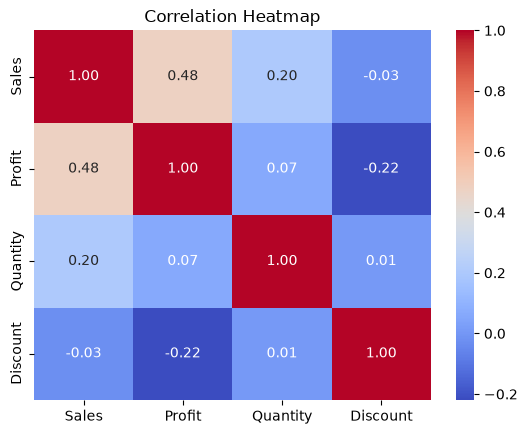

In [165]:
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

## 8. Yearly Sales and Profit Analysis

In [166]:
df['Order Date']=pd.to_datetime(df['Order Date'],errors='coerce')
df['Year']=df['Order Date'].dt.year
print(df[['Order Date','Year']].head())

  Order Date  Year
0 2016-11-08  2016
1 2016-11-08  2016
2 2016-06-12  2016
3 2015-10-11  2015
4 2015-10-11  2015


In [167]:
df['Year']=df['Order Date'].dt.year
print(df[['Order Date','Year']].head())

  Order Date  Year
0 2016-11-08  2016
1 2016-11-08  2016
2 2016-06-12  2016
3 2015-10-11  2015
4 2015-10-11  2015


In [168]:
yearly_sales=df.groupby('Year')['Sales'].sum().reset_index()
print(yearly_sales)

   Year        Sales
0  2014  484247.4981
1  2015  470532.5090
2  2016  609205.5980
3  2017  733215.2552


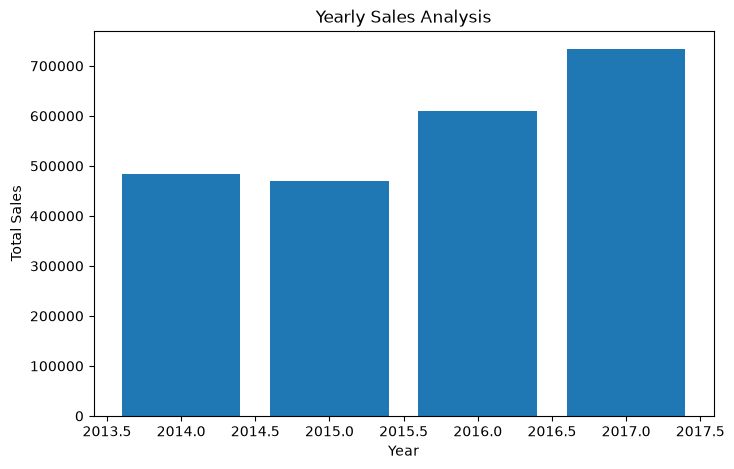

In [84]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(yearly_sales['Year'],yearly_sales['Sales'])
plt.title('Yearly Sales Analysis')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.show()

In [85]:
yearly_profit=df.groupby('Year')['Profit'].sum().reset_index()
print(yearly_profit)

   Year      Profit
0  2014  49543.9741
1  2015  61618.6037
2  2016  81795.1743
3  2017  93439.2696


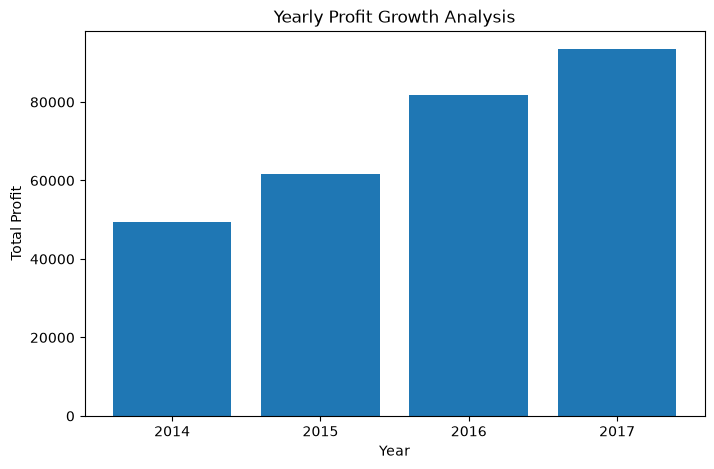

In [86]:
plt.figure(figsize=(8,5))
plt.bar(yearly_profit['Year'],yearly_profit['Profit'])
plt.title('Yearly Profit Growth Analysis')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.xticks(yearly_profit['Year'])
plt.show()

In [87]:
yearly_comparison=pd.merge(yearly_sales,yearly_profit,on='Year')
print(yearly_comparison)

   Year        Sales      Profit
0  2014  484247.4981  49543.9741
1  2015  470532.5090  61618.6037
2  2016  609205.5980  81795.1743
3  2017  733215.2552  93439.2696


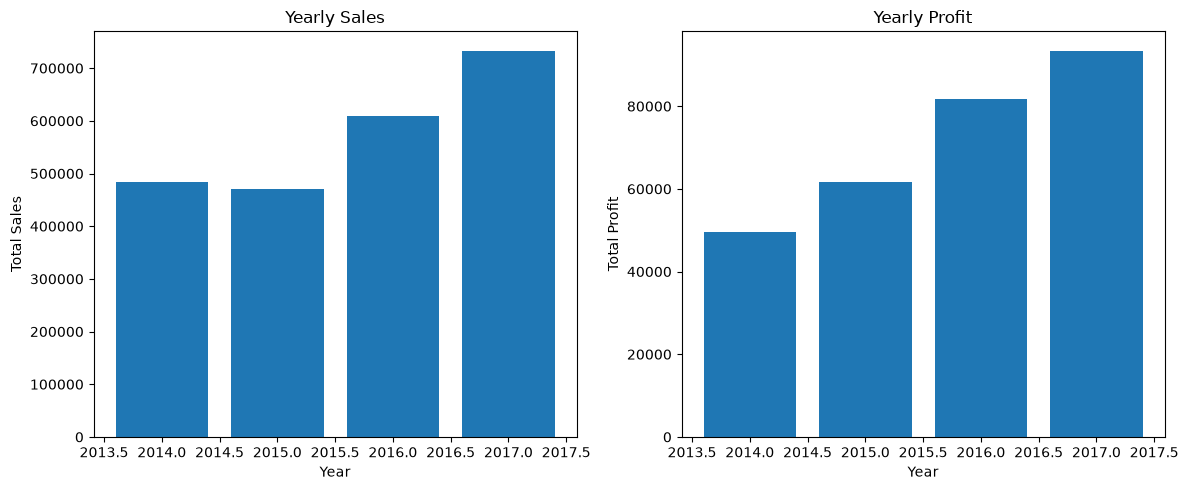

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Yearly Sales
axes[0].bar(yearly_comparison['Year'],
            yearly_comparison['Sales'])

axes[0].set_title('Yearly Sales')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Total Sales')

# Yearly Profit
axes[1].bar(yearly_comparison['Year'],
            yearly_comparison['Profit'])

axes[1].set_title('Yearly Profit')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Total Profit')

plt.tight_layout()
plt.show()

In [89]:
yearly_comparison=yearly_comparison.sort_values('Year')
yearly_comparison['Sales_Growth_%']=(yearly_comparison['Sales'].pct_change()*100)
print(yearly_comparison)

   Year        Sales      Profit  Sales_Growth_%
0  2014  484247.4981  49543.9741             NaN
1  2015  470532.5090  61618.6037       -2.832227
2  2016  609205.5980  81795.1743       29.471521
3  2017  733215.2552  93439.2696       20.355962


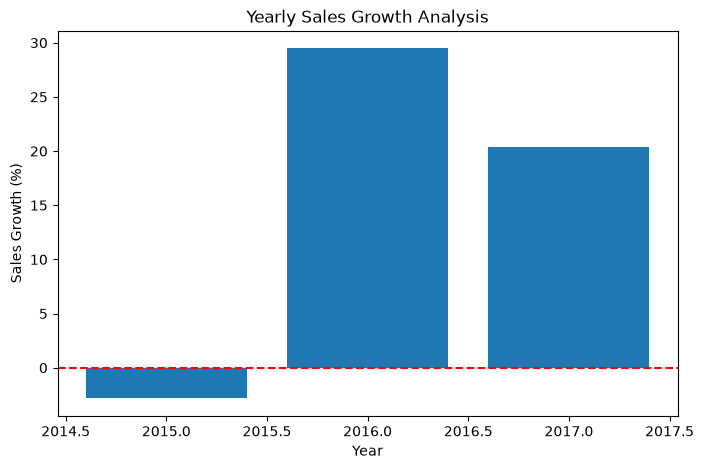

In [90]:
growth_data=yearly_comparison[yearly_comparison['Sales_Growth_%'].notna()]
plt.figure(figsize=(8,5))
plt.bar(growth_data['Year'],
        growth_data['Sales_Growth_%'])
plt.title('Yearly Sales Growth Analysis')
plt.xlabel('Year')
plt.ylabel('Sales Growth (%)')
plt.axhline(y=0,color='red',linestyle='--')
plt.show()

In [91]:
yearly_comparison=yearly_comparison.sort_values('Year')
yearly_comparison['Profit_Growth_%']=(yearly_comparison['Profit'].pct_change()*100)
print(yearly_comparison)

   Year        Sales      Profit  Sales_Growth_%  Profit_Growth_%
0  2014  484247.4981  49543.9741             NaN              NaN
1  2015  470532.5090  61618.6037       -2.832227        24.371540
2  2016  609205.5980  81795.1743       29.471521        32.744284
3  2017  733215.2552  93439.2696       20.355962        14.235675


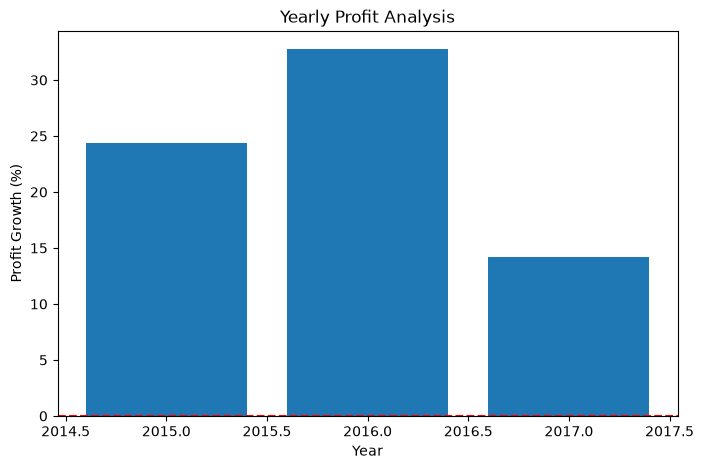

In [92]:
profit_growth_data=yearly_comparison[yearly_comparison['Profit_Growth_%'].notna()]
plt.figure(figsize=(8,5))
plt.bar(
    profit_growth_data['Year'],
    profit_growth_data['Profit_Growth_%']
)
plt.title('Yearly Profit Analysis')
plt.xlabel('Year')
plt.ylabel('Profit Growth (%)')
plt.axhline(y=0,color='red',linestyle='--')
plt.show()

In [93]:
product_sales=df.groupby('Product Name')['Sales'].sum()
top_10_products=product_sales.sort_values(ascending=False).head(10)
print(top_10_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


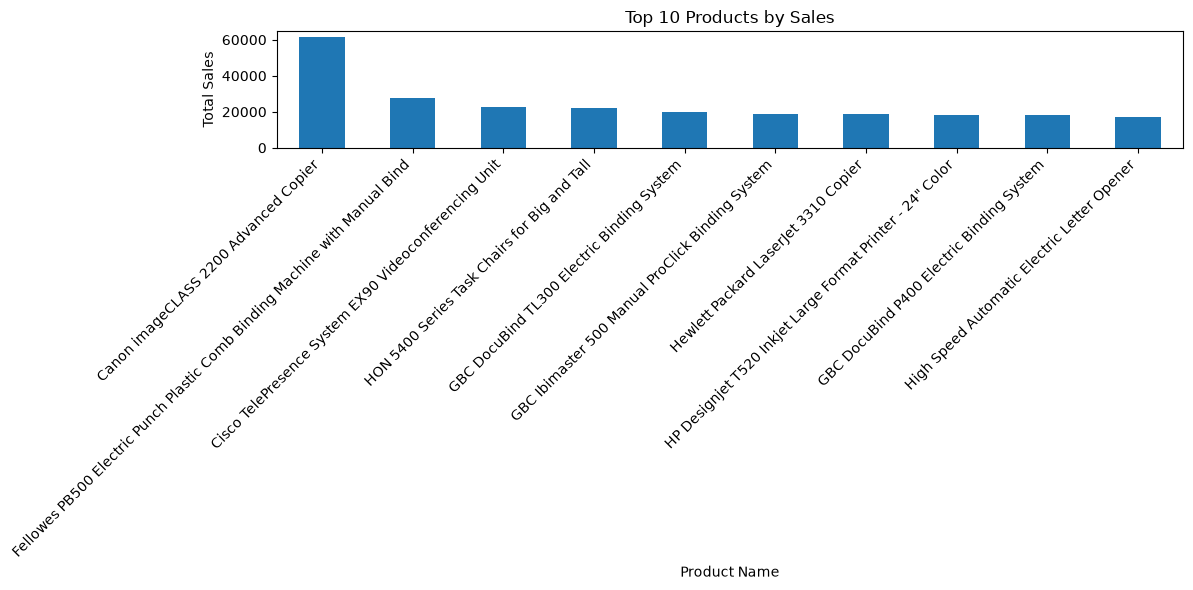

In [94]:
top_10_products.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 Products by Sales')
plt.xlabel('Product Name')
plt.ylabel('Total Sales')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [95]:
product_profit=df.groupby('Product Name')['Profit'].sum()
top_10_profit_products=product_profit.sort_values(ascending=False).head(10)
print(top_10_profit_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


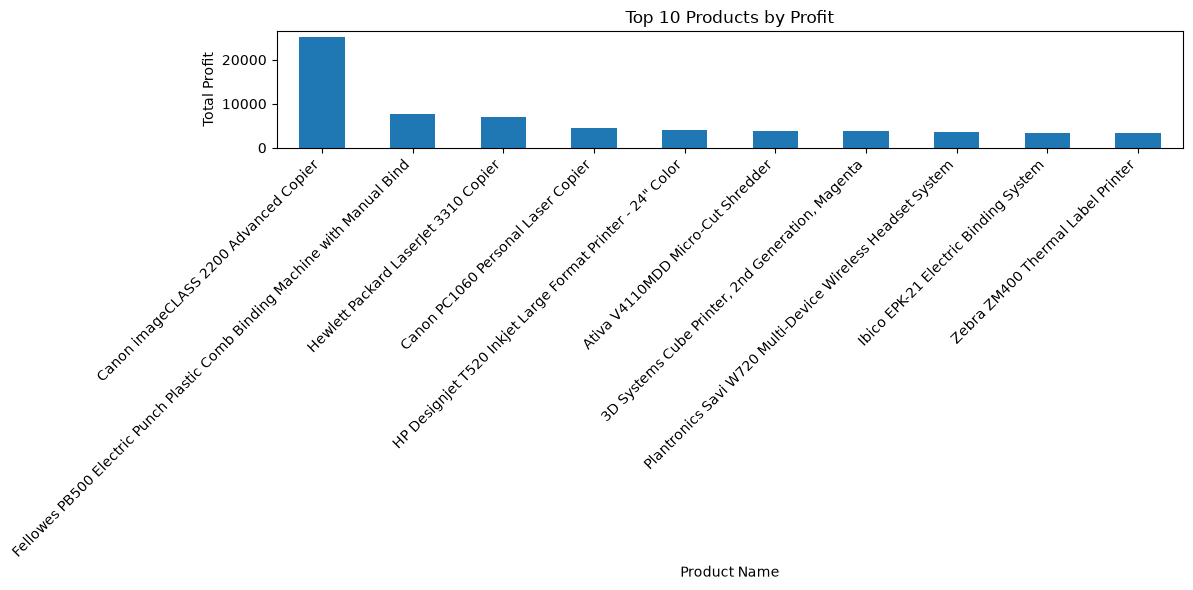

In [96]:
top_10_profit_products.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 Products by Profit')
plt.xlabel('Product Name')
plt.ylabel('Total Profit')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [97]:
product_profit = df.groupby('Product Name')['Profit'].sum()
loss_products = product_profit[product_profit < 0]
print("Total Loss-Making Products:", len(loss_products))
print("\nTop 10 Loss-Making Products:")
print(loss_products.sort_values().head(10))

Total Loss-Making Products: 301

Top 10 Loss-Making Products:
Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


In [98]:
bottom_10_products=product_profit.sort_values(ascending=True).head(10)
print(bottom_10_products)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


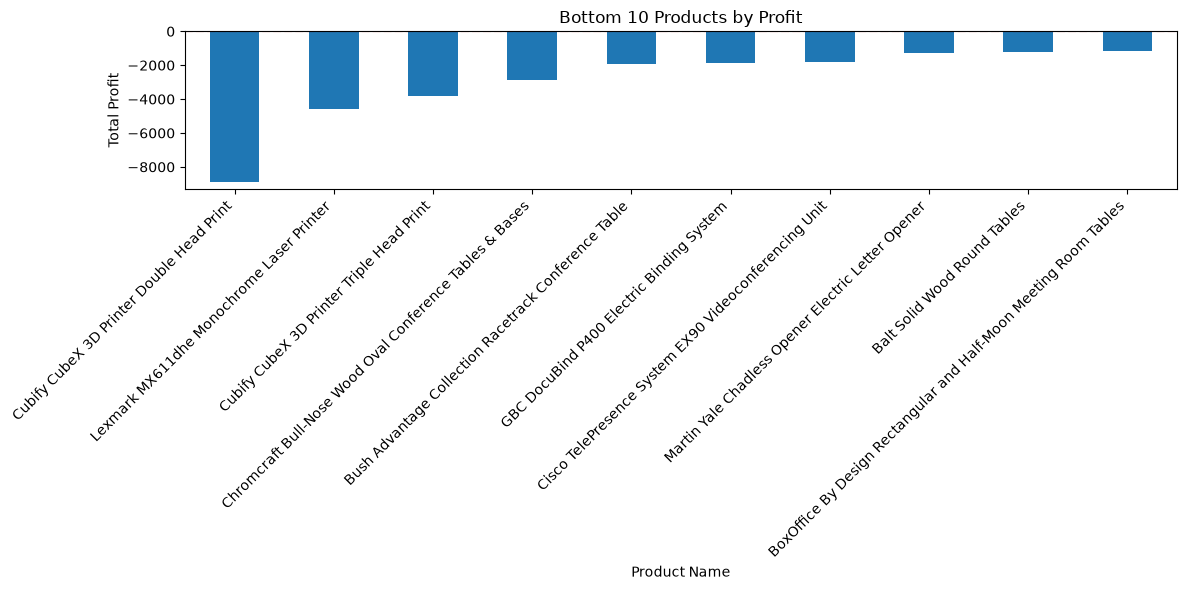

In [99]:
bottom_10_products.plot(kind='bar',figsize=(12,6))
plt.title('Bottom 10 Products by Profit')
plt.xlabel('Product Name')
plt.ylabel('Total Profit')
plt.xticks(rotation=45, ha='right')
plt.axhline(y=0,color='red',linestyle='--')
plt.tight_layout()
plt.show()

In [100]:
category_profit=df.groupby('Category')['Profit'].sum()
print(category_profit)

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


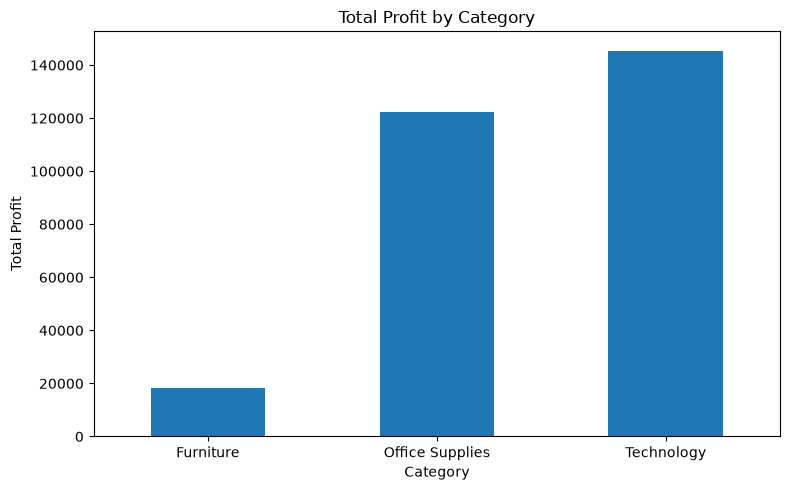

In [101]:
category_profit.plot(kind='bar',figsize=(8,5))
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Regional and State-wise Analysis

In [102]:
region_profit=df.groupby('Region')['Profit'].sum()
print(region_profit)

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


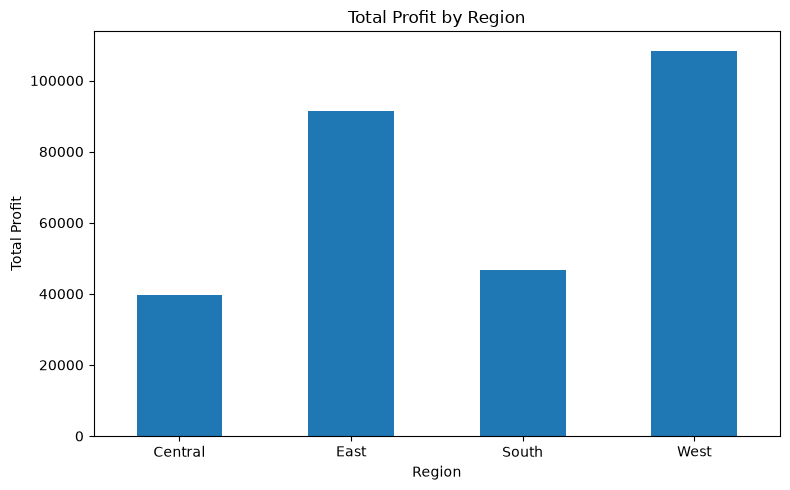

In [103]:
region_profit.plot(kind='bar',figsize=(8,5))
plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [104]:
state_sales=df.groupby('State')['Sales'].sum()
state_sales=state_sales.sort_values(ascending=False)
print(state_sales.head(10))

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64


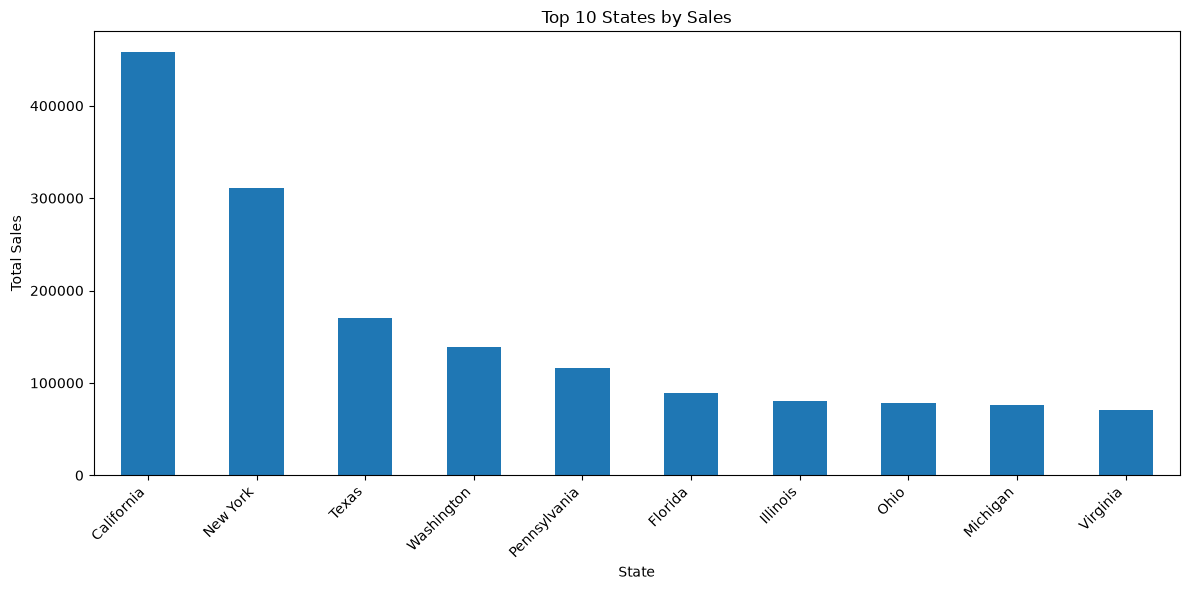

In [105]:
top_10_states=state_sales.head(10)
top_10_states.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 States by Sales')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [106]:
bottom_10_states=state_sales.tail(10)
print(bottom_10_states)

State
New Mexico              4783.522
Iowa                    4579.760
Idaho                   4382.486
Kansas                  2914.310
District of Columbia    2865.020
Wyoming                 1603.136
South Dakota            1315.560
Maine                   1270.530
West Virginia           1209.824
North Dakota             919.910
Name: Sales, dtype: float64


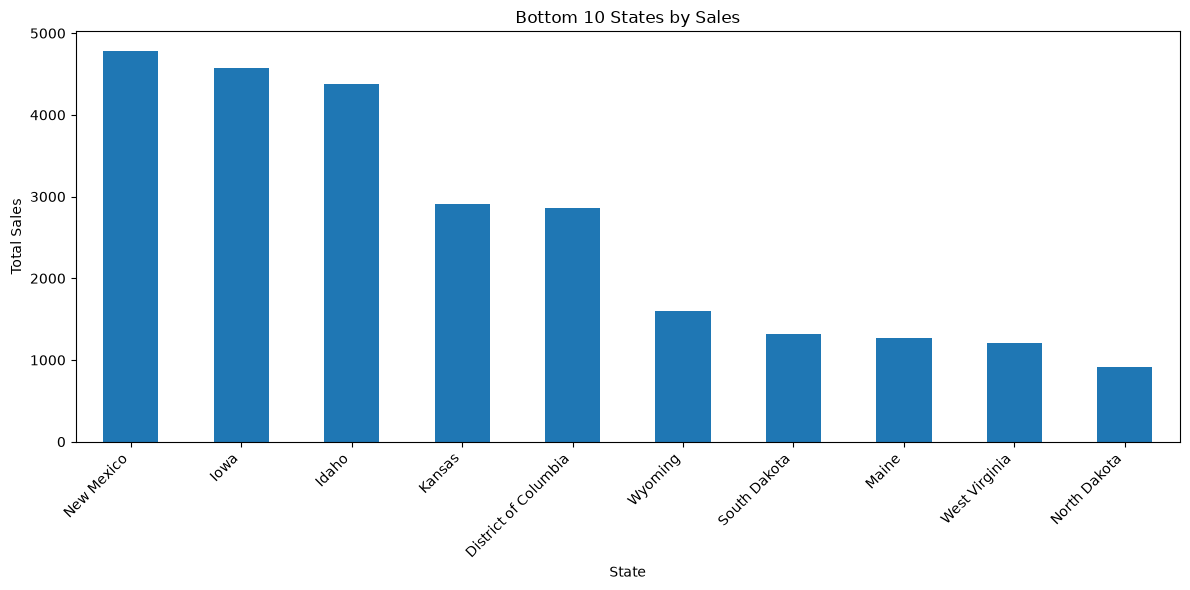

In [107]:
bottom_10_states.plot(kind='bar',figsize=(12,6))
plt.title('Bottom 10 States by Sales')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [108]:
state_profit=df.groupby('State')['Profit'].sum()
state_profit=state_profit.sort_values(ascending=False)
print(state_profit.head(10))

State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Indiana       18382.9363
Georgia       16250.0433
Kentucky      11199.6966
Minnesota     10823.1874
Delaware       9977.3748
Name: Profit, dtype: float64


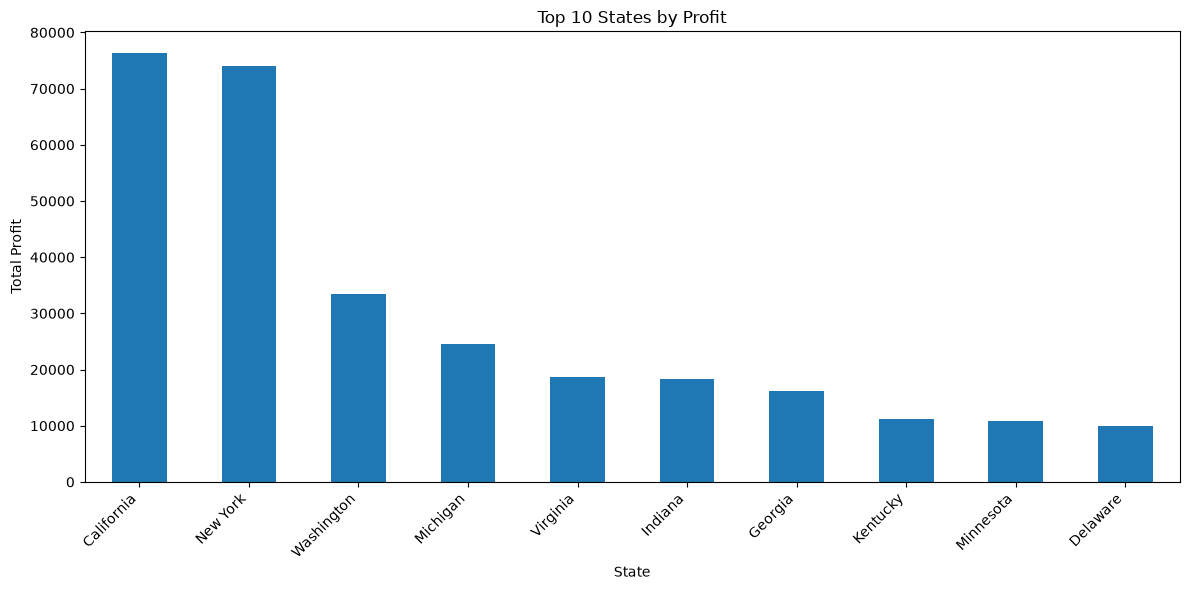

In [109]:
top_10_profit_states=state_profit.head(10)
top_10_profit_states.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 States by Profit')
plt.xlabel('State')
plt.ylabel('Total Profit')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [110]:
bottom_10_profit_states=state_profit.sort_values(ascending=True).head(10)
print(bottom_10_profit_states)

State
Texas            -25729.3563
Ohio             -16971.3766
Pennsylvania     -15559.9603
Illinois         -12607.8870
North Carolina    -7490.9122
Colorado          -6527.8579
Tennessee         -5341.6936
Arizona           -3427.9246
Florida           -3399.3017
Oregon            -1190.4705
Name: Profit, dtype: float64


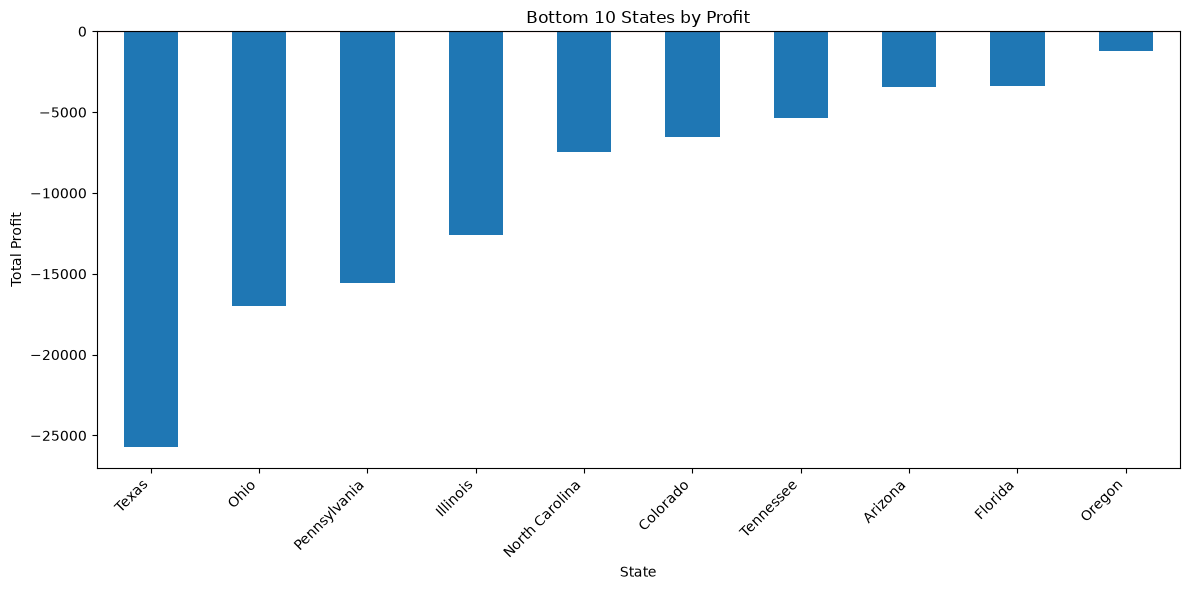

In [111]:
bottom_10_profit_states.plot(kind='bar',figsize=(12,6))
plt.title('Bottom 10 States by Profit')
plt.xlabel('State')
plt.ylabel('Total Profit')
plt.xticks(rotation=45,ha='right')
plt.axhline(y=0,color='red',linestyle='-')
plt.tight_layout()
plt.show()

In [112]:
print(bottom_10_profit_states)

State
Texas            -25729.3563
Ohio             -16971.3766
Pennsylvania     -15559.9603
Illinois         -12607.8870
North Carolina    -7490.9122
Colorado          -6527.8579
Tennessee         -5341.6936
Arizona           -3427.9246
Florida           -3399.3017
Oregon            -1190.4705
Name: Profit, dtype: float64


## 10. Category and Profit Margin Analysis

In [113]:
category_analysis=df.groupby('Category')[['Sales','Profit']].sum()
print(category_analysis)

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


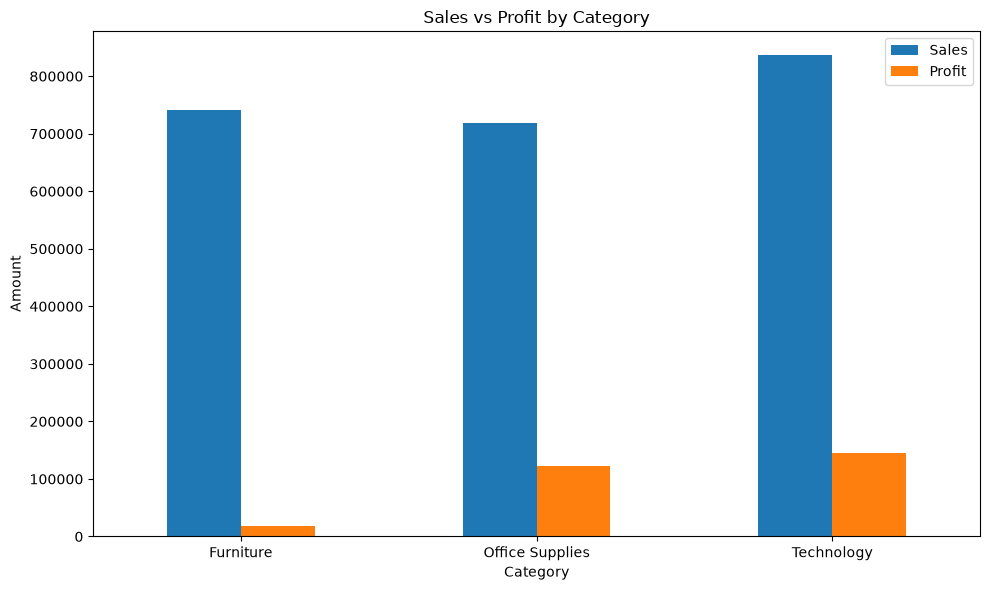

In [114]:
category_analysis.plot(kind='bar',figsize=(10,6))
plt.title('Sales vs Profit by Category')
plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [115]:
category_analysis['Profit_Margin_%']=(category_analysis['Profit']/category_analysis['Sales'])*100
print(category_analysis)

                       Sales       Profit  Profit_Margin_%
Category                                                  
Furniture        741999.7953   18451.2728         2.486695
Office Supplies  719047.0320  122490.8008        17.035158
Technology       836154.0330  145454.9481        17.395712


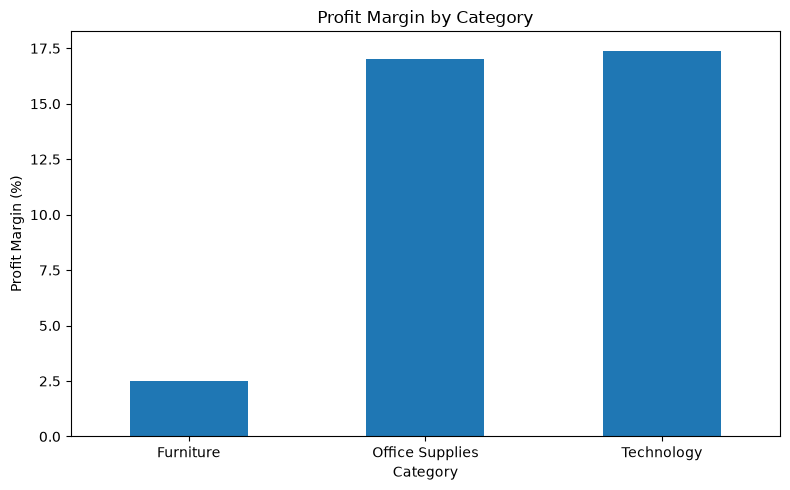

In [116]:
category_analysis['Profit_Margin_%'].plot(kind='bar',figsize=(8,5))
plt.title('Profit Margin by Category')
plt.xlabel('Category')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Discount Impact Analysis

In [117]:
discount_profit=df.groupby('Discount')['Profit'].mean()
print(discount_profit)

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


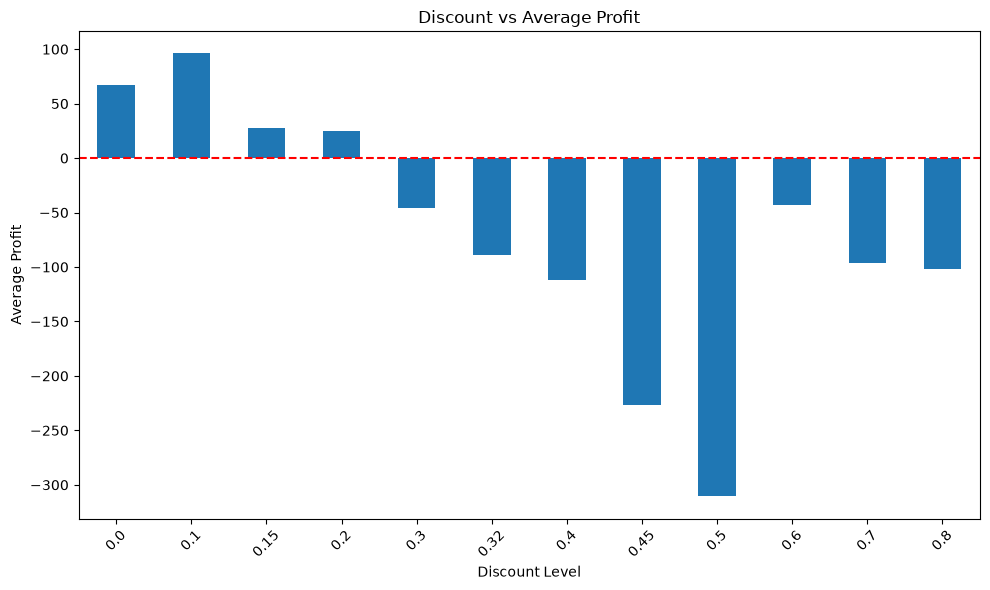

In [118]:
discount_profit.plot(kind='bar',figsize=(10,6))
plt.title('Discount vs Average Profit')
plt.xlabel('Discount Level')
plt.ylabel('Average Profit')
plt.xticks(rotation=45)
plt.axhline(y=0,color='red',linestyle='--')
plt.tight_layout()
plt.show()

In [119]:
discount_sales=df.groupby('Discount')['Sales'].mean()
print(discount_sales)

Discount
0.00    226.742074
0.10    578.397351
0.15    529.971567
0.20    209.076940
0.30    454.742974
0.32    536.794770
0.40    565.134874
0.45    498.634000
0.50    892.705152
0.60     48.150000
0.70     97.177708
0.80     56.545853
Name: Sales, dtype: float64


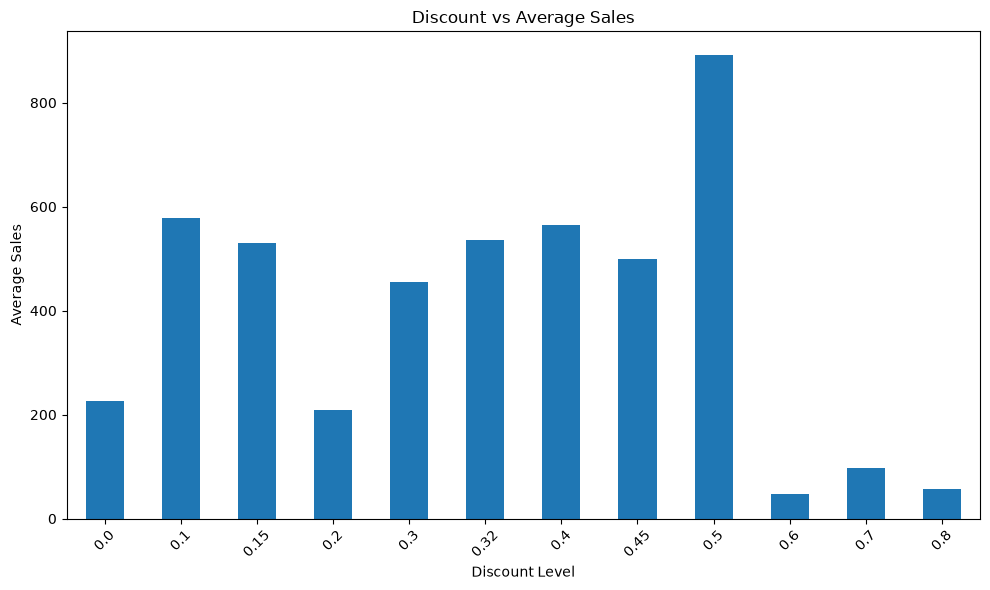

In [120]:
discount_sales.plot(kind='bar',figsize=(10,6))
plt.title('Discount vs Average Sales')
plt.xlabel('Discount Level')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 12. Shipping Mode and Customer Segment Analysis

In [121]:
shipping_analysis=df.groupby('Ship Mode')[['Sales','Profit']].sum()
print(shipping_analysis)

                       Sales       Profit
Ship Mode                                
First Class     3.514284e+05   48969.8399
Same Day        1.283631e+05   15891.7589
Second Class    4.591936e+05   57446.6354
Standard Class  1.358216e+06  164088.7875


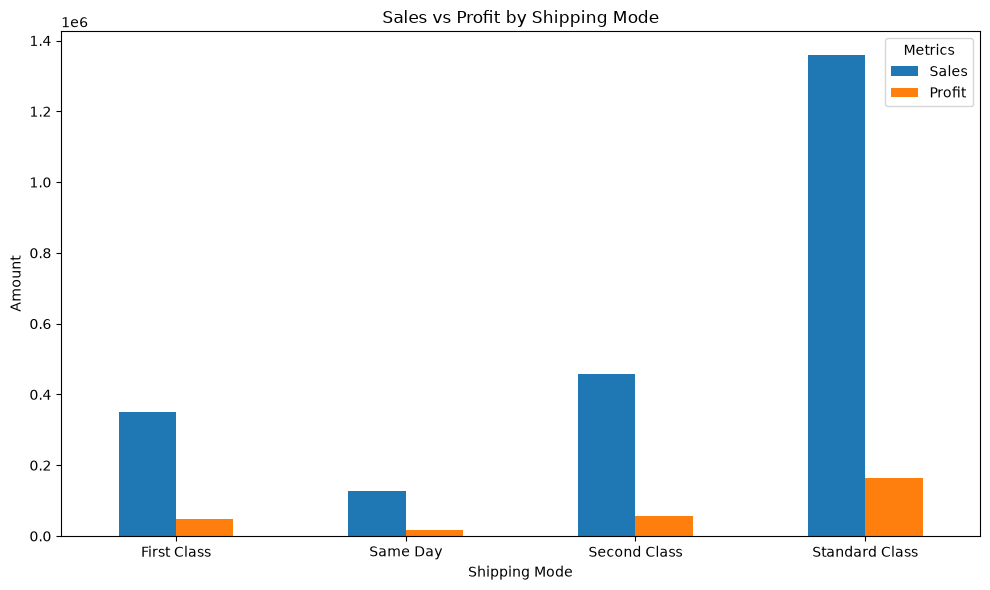

In [122]:
shipping_analysis.plot(kind='bar',figsize=(10,6))
plt.title('Sales vs Profit by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

In [123]:
segment_analysis=df.groupby('Segment')[['Sales','Profit']].sum()
print(segment_analysis)

                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


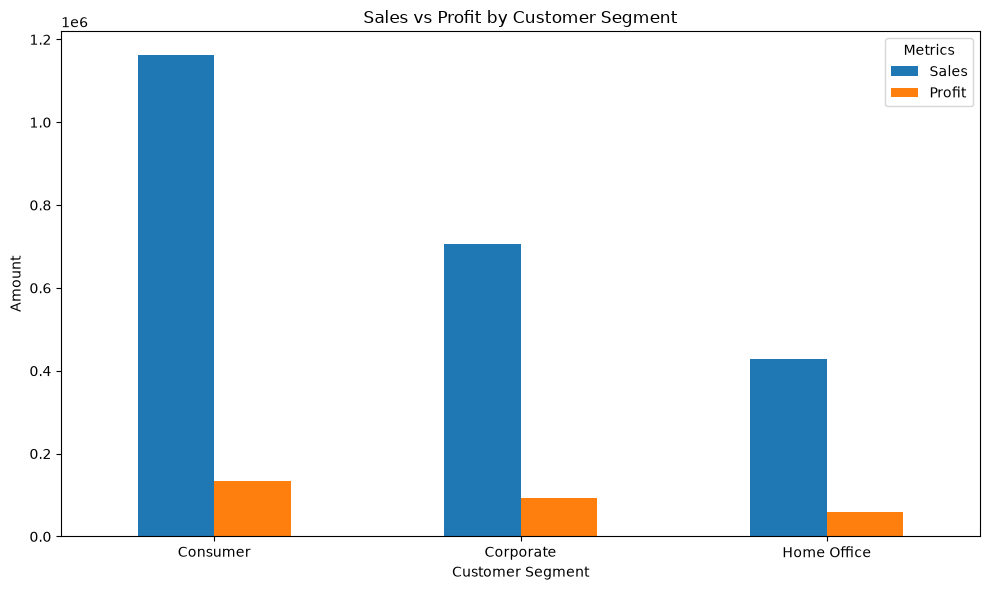

In [124]:
segment_analysis.plot(kind='bar',figsize=(10,6))
plt.title('Sales vs Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

## 13. Customer Analysis

In [125]:
customer_sales=df.groupby('Customer Name')['Sales'].sum()
customer_sales=customer_sales.sort_values(ascending=False)
print(customer_sales.head(10))

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


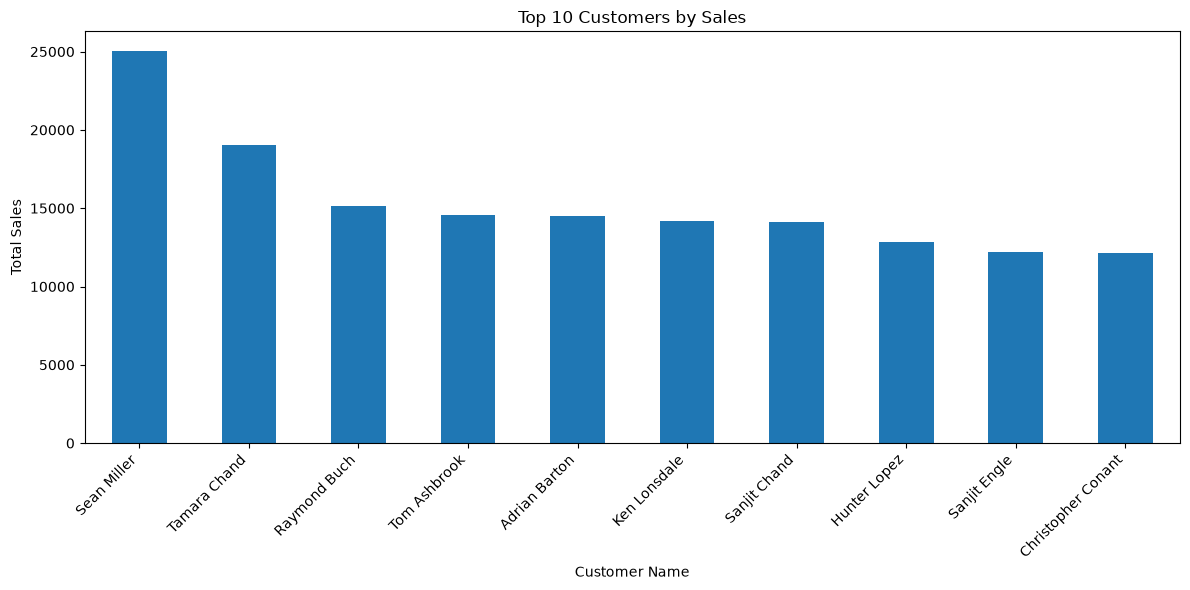

In [126]:
top_10_customers=customer_sales.head(10)
top_10_customers.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer Name')
plt.ylabel('Total Sales')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [127]:
customer_profit=df.groupby('Customer Name')['Profit'].sum()
customer_profit=customer_profit.sort_values(ascending=False)
print(customer_profit.head(10))

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


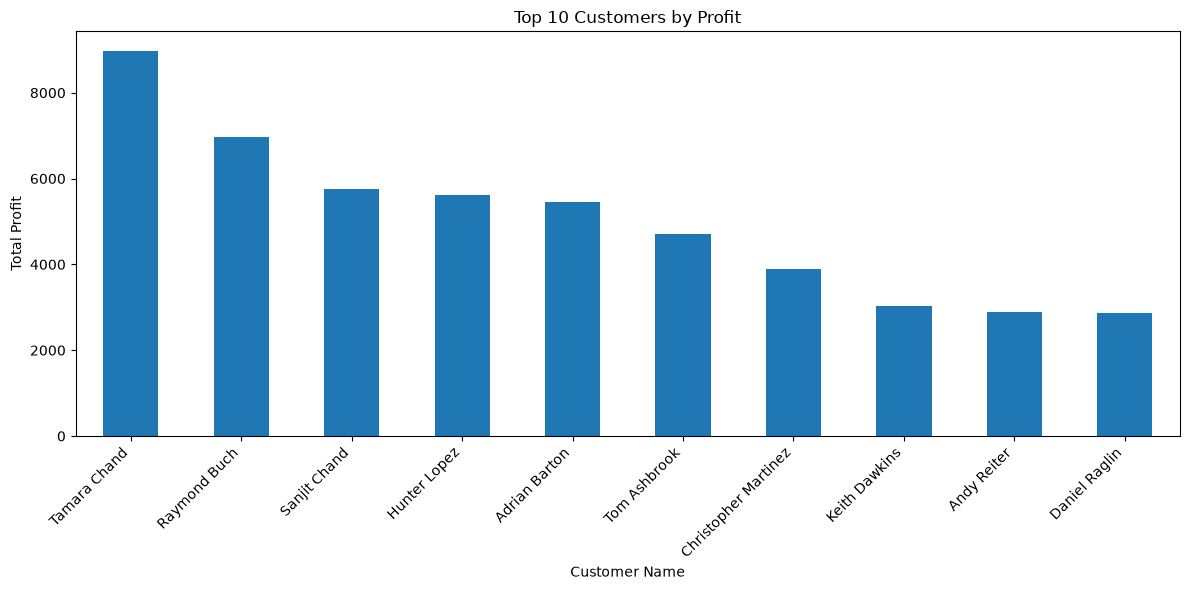

In [128]:
top_10_customers_profit=customer_profit.head(10)
top_10_customers_profit.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 Customers by Profit')
plt.xlabel('Customer Name')
plt.ylabel('Total Profit')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [129]:
customer_orders=df.groupby('Customer Name')['Order ID'].nunique()
print(customer_orders.head(10))

Customer Name
Aaron Bergman          3
Aaron Hawkins          7
Aaron Smayling         7
Adam Bellavance        8
Adam Hart             10
Adam Shillingsburg     9
Adrian Barton         10
Adrian Hane            7
Adrian Shami           2
Aimee Bixby            5
Name: Order ID, dtype: int64


In [130]:
top_10_repeat_customers=customer_orders.sort_values(ascending=False).head(10)
print(top_10_repeat_customers)

Customer Name
Emily Phan             17
Sally Hughsby          13
Noel Staavos           13
Patrick Gardner        13
Zuschuss Carroll       13
Joel Eaton             13
Erin Ashbrook          13
Chloris Kastensmidt    13
Suzanne McNair         12
Rick Bensley           12
Name: Order ID, dtype: int64


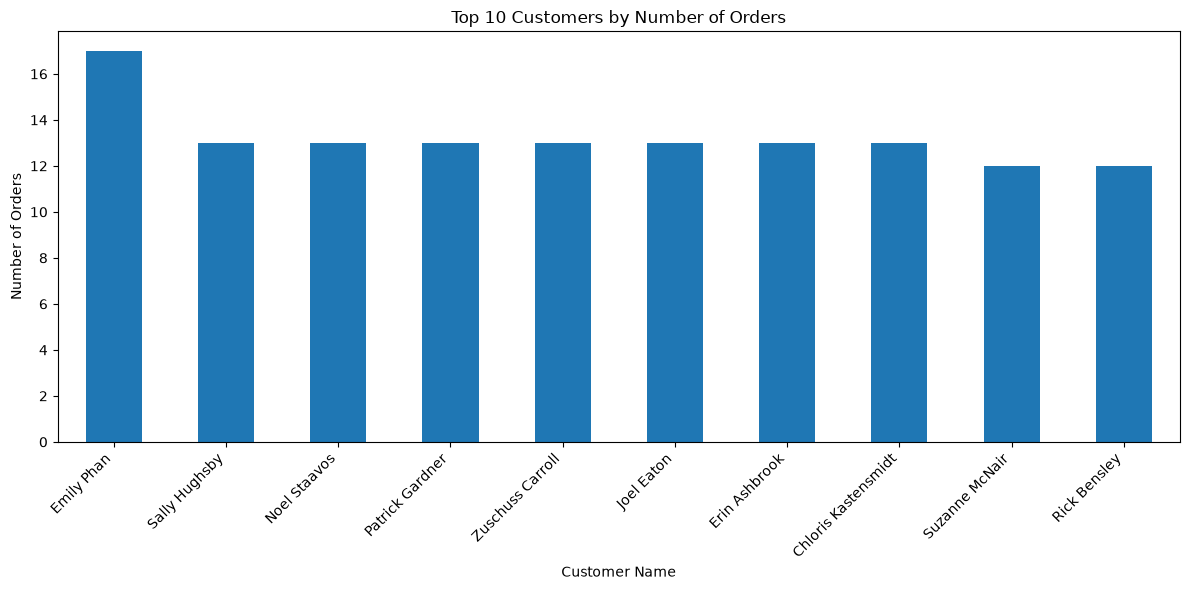

In [131]:
top_10_repeat_customers.plot(kind='bar',figsize=(12,6))
plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Customer Name')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

## 14. Key Performance Indicators (KPIs)

In [132]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer Name'].nunique()
average_discount = df['Discount'].mean()
profit_margin = (total_profit / total_sales) * 100

print("OVERALL BUSINESS PERFORMANCE")
print("----------------------------")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Discount:", round(average_discount * 100, 2), "%")
print("Overall Profit Margin:", round(profit_margin, 2), "%")

OVERALL BUSINESS PERFORMANCE
----------------------------
Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Average Discount: 15.62 %
Overall Profit Margin: 12.47 %


In [133]:
import pandas as pd
kpi_summary=pd.DataFrame({
    'Metric':['Total Sales','Total Profit','Total Orders','Total Customers','Average Discount(%)','Overall Profit Margin(%)'],
    'Value':[round(total_sales,2),
             round(total_profit,2),
             total_orders,
             total_customers,
             round(average_discount*100,2),
             round(profit_margin,2)
            ]
})
kpi_summary

,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Total Orders,5009.00
3,Total Customers,793.00
4,Average Discount(%),15.62
5,Overall Profit Margin(%),12.47


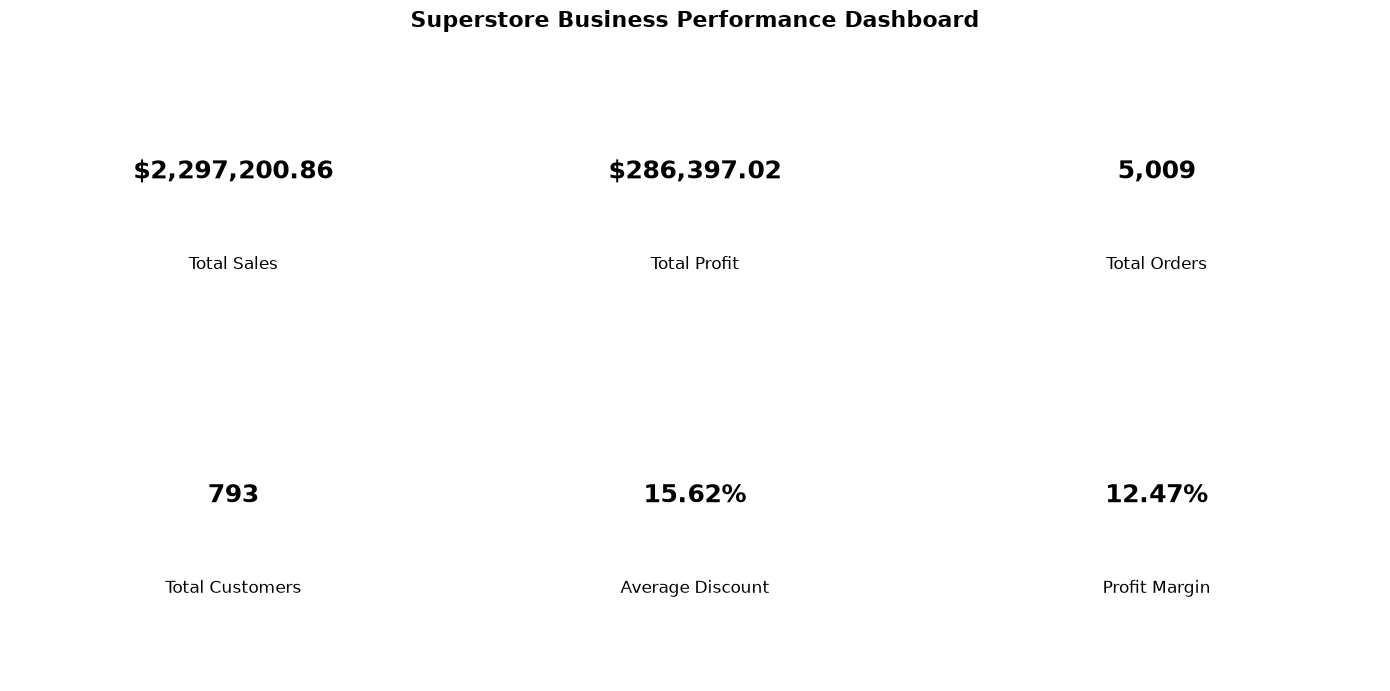

In [134]:
fig,axes=plt.subplots(2,3,figsize=(14, 7))
kpis=[
    ("Total Sales",f"${total_sales:,.2f}"),
    ("Total Profit",f"${total_profit:,.2f}"),
    ("Total Orders",f"{total_orders:,}"),
    ("Total Customers",f"{total_customers:,}"),
    ("Average Discount",f"{average_discount * 100:.2f}%"),
    ("Profit Margin",f"{profit_margin:.2f}%")
]
for ax,(title,value) in zip(axes.flatten(),kpis):
    ax.text(
        0.5,0.6,value,
        ha='center',va='center',
        fontsize=18,fontweight='bold'
    )
    ax.text(
        0.5,0.3,title,
        ha='center', va='center',
        fontsize=12
    )
    ax.set_axis_off()
plt.suptitle(
    'Superstore Business Performance Dashboard',
    fontsize=16,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

## 15. Business Insights and Recommendations

In [135]:
best_sales_category=category_analysis['Sales'].idxmax()
best_profit_category=category_analysis['Profit'].idxmax()
print('Category with Highest Sales:',best_sales_category)
print('Category with Highest Profit:',best_profit_category)

Category with Highest Sales: Technology
Category with Highest Profit: Technology


In [136]:
best_state=state_profit.idxmax()
lowest_profit_state=state_profit.idxmin()
print('State with Highest Profit:',best_state)
print('State with Lowest Profit:',lowest_profit_state)

State with Highest Profit: California
State with Lowest Profit: Texas


In [137]:
region_profit=df.groupby('Region')['Profit'].sum()
print(region_profit)

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


In [138]:
state_profit=df.groupby('State')['Profit'].sum()
print(state_profit)

State
Alabama                  5786.8253
Arizona                 -3427.9246
Arkansas                 4008.6871
California              76381.3871
Colorado                -6527.8579
Connecticut              3511.4918
Delaware                 9977.3748
District of Columbia     1059.5893
Florida                 -3399.3017
Georgia                 16250.0433
Idaho                     826.7231
Illinois               -12607.8870
Indiana                 18382.9363
Iowa                     1183.8119
Kansas                    836.4435
Kentucky                11199.6966
Louisiana                2196.1023
Maine                     454.4862
Maryland                 7031.1788
Massachusetts            6785.5016
Michigan                24463.1876
Minnesota               10823.1874
Mississippi              3172.9762
Missouri                 6436.2105
Montana                  1833.3285
Nebraska                 2037.0942
Nevada                   3316.7659
New Hampshire            1706.5028
New Jersey    

In [141]:
best_region=region_profit.idxmax()
lowest_profit_region=region_profit.idxmin()
best_state=state_profit.idxmax()
lowest_profit_state=state_profit.idxmin()

In [142]:
print('Best Performing Region:',best_region)
print('Lowest Performing Region:',lowest_profit_region)
print('Best Performing State:',best_state)
print('Lowest Profit State:',lowest_profit_state)

Best Performing Region: West
Lowest Performing Region: Central
Best Performing State: California
Lowest Profit State: Texas


In [143]:
business_insights=pd.DataFrame({
    'Metric':[
        'Highest Profit Region',
        'Lowest Profit Region',
        'Highest Profit State',
        'Lowest Profit State',
    ],
    'Result':[
        best_region,
        lowest_profit_region,
        best_state,
        lowest_profit_state
    ]
})
business_insights

,Metric,Result
0,Highest Profit Region,West
1,Lowest Profit Region,Central
2,Highest Profit State,California
3,Lowest Profit State,Texas


In [144]:
print('Region-wise Profit:')
print(region_profit.sort_values(ascending=False))
print('\nState-wise Profit:')
print(state_profit.sort_values(ascending=False).head(5))

Region-wise Profit:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

State-wise Profit:
State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Name: Profit, dtype: float64


In [145]:
profit_difference=(region_profit.max()-region_profit.min())
print('Profit Difference:',round(profit_difference,2))

Profit Difference: 68712.09


In [146]:
region_profit_percentage=(region_profit/region_profit.sum())*100
print(region_profit_percentage.round(2))

Region
Central    13.86
East       31.96
South      16.32
West       37.86
Name: Profit, dtype: float64


In [147]:
top_two_regions=(region_profit_percentage['West']+region_profit_percentage['East'])
print('West and East Combined Profit Contribution:',round(top_two_regions,2),"%")

West and East Combined Profit Contribution: 69.81 %


In [148]:
state_profit_percentage=(state_profit/state_profit.sum())*100
print(
    state_profit_percentage.sort_values(ascending=False).head(10).round(2))

State
California    26.67
New York      25.85
Washington    11.66
Michigan       8.54
Virginia       6.49
Indiana        6.42
Georgia        5.67
Kentucky       3.91
Minnesota      3.78
Delaware       3.48
Name: Profit, dtype: float64


In [149]:
category_profit=df.groupby('Category')['Profit'].sum()
category_profit_percentage=(category_profit/category_profit.sum())*100
print(category_profit_percentage.map(lambda x:f"{x:.2f}%"))

Category
Furniture           6.44%
Office Supplies    42.77%
Technology         50.79%
Name: Profit, dtype: str


In [150]:
segment_profit=df.groupby('Segment')['Profit'].sum()
segment_profit_percentage=(segment_profit/segment_profit.sum())*100
print(segment_profit_percentage.map(lambda x:f"{x:2f}%"))

Segment
Consumer       46.829820%
Corporate      32.115953%
Home Office    21.054227%
Name: Profit, dtype: str


In [151]:
shipping_profit=df.groupby('Ship Mode')['Profit'].sum()
shipping_profit_percentage=(shipping_profit/shipping_profit.sum())*100
print(shipping_profit_percentage.map(lambda x:f"{x:.2f}%"))

Ship Mode
First Class       17.10%
Same Day           5.55%
Second Class      20.06%
Standard Class    57.29%
Name: Profit, dtype: str


In [152]:
print(shipping_profit_percentage.sort_values(ascending=False).to_string())

Ship Mode
Standard Class    57.294167
Second Class      20.058391
First Class       17.098586
Same Day           5.548856


In [153]:
segment_sales=df.groupby('Segment')['Sales'].sum()
segment_sales_percentage=(segment_sales/segment_sales.sum())*100
print(segment_sales_percentage.sort_values(ascending=False).round(2))

Segment
Consumer       50.56
Corporate      30.74
Home Office    18.70
Name: Sales, dtype: float64


In [154]:
category_sales=df.groupby('Category')['Sales'].sum()
category_sales_percentage=(category_sales/category_sales.sum())*100
print(category_sales_percentage.sort_values(ascending=False).round(2))

Category
Technology         36.4
Furniture          32.3
Office Supplies    31.3
Name: Sales, dtype: float64


In [155]:
product_sales=df.groupby('Product Name')['Sales'].sum()
product_sales_percentage=(product_sales/product_sales.sum())*100
print(product_sales_percentage.sort_values(ascending=False).head(10).round(2))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          2.68
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    1.20
Cisco TelePresence System EX90 Videoconferencing Unit                          0.99
HON 5400 Series Task Chairs for Big and Tall                                   0.95
GBC DocuBind TL300 Electric Binding System                                     0.86
GBC Ibimaster 500 Manual ProClick Binding System                               0.83
Hewlett Packard LaserJet 3310 Copier                                           0.82
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      0.80
GBC DocuBind P400 Electric Binding System                                      0.78
High Speed Automatic Electric Letter Opener                                    0.74
Name: Sales, dtype: float64


In [156]:
product_profit=df.groupby('Product Name')['Profit'].sum()
product_profit_percentage=(product_profit/product_profit.sum())*100
print(product_profit_percentage.sort_values(ascending=False).head(10).round(2))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          8.80
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    2.71
Hewlett Packard LaserJet 3310 Copier                                           2.44
Canon PC1060 Personal Laser Copier                                             1.60
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      1.43
Ativa V4110MDD Micro-Cut Shredder                                              1.32
3D Systems Cube Printer, 2nd Generation, Magenta                               1.30
Plantronics Savi W720 Multi-Device Wireless Headset System                     1.29
Ibico EPK-21 Electric Binding System                                           1.17
Zebra ZM400 Thermal Label Printer                                              1.17
Name: Profit, dtype: float64


In [157]:
recommendations = pd.DataFrame({
    'Area': [
        'Regional Performance',
        'Category Performance',
        'Customer Segments',
        'Shipping Performance',
        'Product Performance'
    ],
    'Recommendation': [
        'Investigate low profitability in the Central region.',
        'Review Furniture pricing, discounts and costs.',
        'Strengthen Consumer and Corporate customer relationships.',
        'Evaluate the costs and profitability of each shipping mode.',
        'Monitor top-selling products and maintain stock availability.'
    ]
})
recommendations

,Area,Recommendation
0,Regional Performance,Investigate low profitability in the Central r...
1,Category Performance,"Review Furniture pricing, discounts and costs."
2,Customer Segments,Strengthen Consumer and Corporate customer rel...
3,Shipping Performance,Evaluate the costs and profitability of each s...
4,Product Performance,Monitor top-selling products and maintain stoc...


## 16. Project Conclusion

In [158]:
project_conclusion = """
The Superstore Sales Analysis project was completed using Python,
Pandas, Matplotlib and Seaborn.

The analysis explored sales, profit, discounts, product performance,
customer segments, regions, states and shipping modes.

Key findings:
1. The West region generated the highest profit.
2. Technology contributed the largest share of category profit.
3. Consumer customers generated the highest sales.
4. Furniture had the lowest category profit contribution.
5. The Canon imageCLASS 2200 was the top product by sales contribution.

The analysis also identified areas for improvement, particularly
regional profitability, Furniture performance and discount management.

Overall, this project demonstrates how Python can be used to clean,
analyse and visualise business data and generate actionable insights.
"""

print(project_conclusion)


The Superstore Sales Analysis project was completed using Python,
Pandas, Matplotlib and Seaborn.

The analysis explored sales, profit, discounts, product performance,
customer segments, regions, states and shipping modes.

Key findings:
1. The West region generated the highest profit.
2. Technology contributed the largest share of category profit.
3. Consumer customers generated the highest sales.
4. Furniture had the lowest category profit contribution.
5. The Canon imageCLASS 2200 was the top product by sales contribution.

The analysis also identified areas for improvement, particularly
regional profitability, Furniture performance and discount management.

Overall, this project demonstrates how Python can be used to clean,
analyse and visualise business data and generate actionable insights.

